In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

In [2]:
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

In [3]:
iris = load_iris()

In [4]:
#X = pd.Dataframe(iris.data)
X = iris.data
y = iris.target

In [5]:
X.shape

(150, 4)

<Axes: >

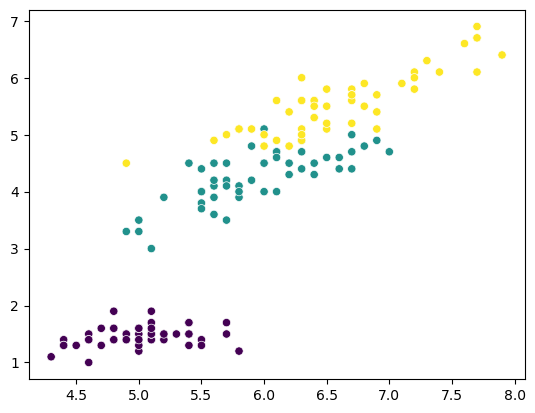

In [6]:
sns.scatterplot(x=X[:,0], y=X[:,2], c=y)

In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [8]:
#Dimentionality reduction
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_scaled)

In [9]:
# Elbow Method
wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, n_init=10)
    kmeans.fit_predict(X_scaled)
    wcss.append(kmeans.inertia_)

<Axes: >

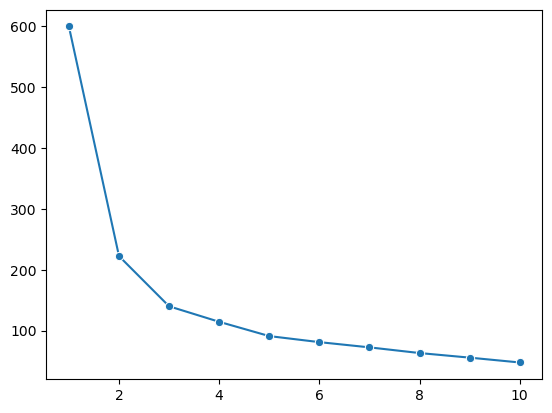

In [10]:
sns.lineplot(x=range(1,11), y=wcss, marker='o')

<Axes: >

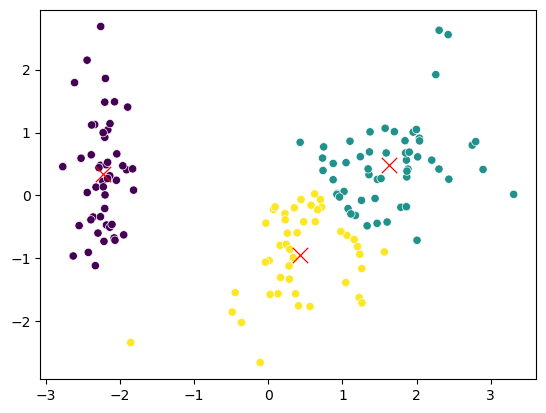

In [11]:
kmeans = KMeans(n_clusters=3)
labels = kmeans.fit_predict(pca_data)
sns.scatterplot(x=pca_data[:,0], y=pca_data[:,1], c=labels)
sns.scatterplot(x=kmeans.cluster_centers_[:,0], y=kmeans.cluster_centers_[:,1], marker='x', c='red', s=122)